# EDA — distribuição, correlações e hipótese de negócio

O alvo é a classe da mediana municipal diária de `risco_fogo`. KPIs: F1 macro e recall da classe alta, interpretados com precisão e matriz de confusão. Todas as análises exploratórias abaixo usam somente os 764 exemplos de treino. A análise foi acrescentada após o congelamento para completar a documentação acadêmica; não houve nova escolha de features, limites, parâmetros ou modelos.

In [1]:
from pathlib import Path
import json, sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'submission/manifest.json').is_file() and (p/'src/fire_risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abra o notebook dentro da pasta extraída ou do clone completo do projeto.')
sys.path.insert(0, str(ROOT/'src'))
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from fire_risk.submission import verify_submission, training_correlations
panel, manifest = verify_submission(ROOT)
def evidence(name):
    return json.loads((ROOT/'submission/evidence'/name).read_text(encoding='utf-8'))
print('Base consolidada íntegra:', len(panel), 'municípios/dia; partições:', manifest['splits'])
print('Modelo congelado:', manifest['model_id'])

training, correlations = training_correlations(panel)
print("Amostra de EDA:", len(training), "exemplos; teste excluído.")

Base consolidada íntegra: 1329 municípios/dia; partições: {'train': 764, 'test': 310, 'validation': 183, 'gap': 72}
Modelo congelado: 852606b93da31ade
Amostra de EDA: 764 exemplos; teste excluído.


## Distribuição do alvo e desbalanceamento

Os gráficos distinguem o índice contínuo de suas três classes ordenadas. Baixo: até 0,40; médio: acima de 0,40 até 0,70; alto: acima de 0,70. São classes do índice observado na amostra selecionada, não ausência/presença física de incêndio. O desbalanceamento justifica métricas por classe e a referência majoritária.

          n  percentual
target                 
baixo   453   59.293194
medio    69    9.031414
alto    242   31.675393


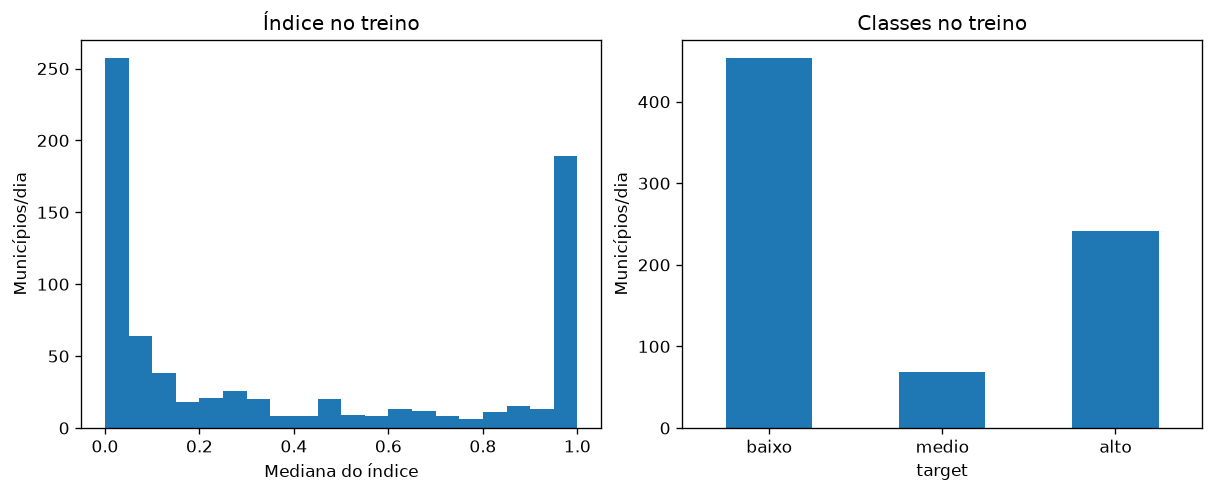

In [2]:
counts = training['target'].value_counts().reindex(['baixo','medio','alto'], fill_value=0)
print(pd.DataFrame({'n':counts,'percentual':100*counts/len(training)}).to_string())
fig, axes = plt.subplots(1,2,figsize=(10,4),layout='constrained')
axes[0].hist(training['target_index'],bins=20); axes[0].set_title('Índice no treino'); axes[0].set_xlabel('Mediana do índice'); axes[0].set_ylabel('Municípios/dia')
counts.plot.bar(ax=axes[1],rot=0); axes[1].set_title('Classes no treino'); axes[1].set_ylabel('Municípios/dia')


## Ausências, distribuições e extremos das features

As regras de cobertura foram aplicadas antes do painel. O número de faltantes aqui se refere somente aos exemplos elegíveis, não aos CSVs originais. O critério 1,5 IQR descreve extremos; não exclui linhas nem altera o modelo. Consultar a auditoria para as ausências e exclusões nas fontes.

         chuva_d2  temperatura_d2  umidade_d2    vento_d2
count  764.000000      764.000000  764.000000  764.000000
mean     2.781178       25.863512   71.768613    1.920217
std      7.801368        2.733445   12.094476    1.034585
min      0.000000       14.200000   32.625000    0.000000
25%      0.000000       24.393750   64.187500    1.179167
50%      0.000000       26.039583   73.954167    1.750000
75%      1.000000       27.771875   80.458333    2.489583
max     67.800000       32.262500  100.000000    6.312500
Ausências: {'chuva_d2': 0, 'temperatura_d2': 0, 'umidade_d2': 0, 'vento_d2': 0}
Extremos 1,5 IQR: {'chuva_d2': 148, 'temperatura_d2': 10, 'umidade_d2': 6, 'vento_d2': 10}


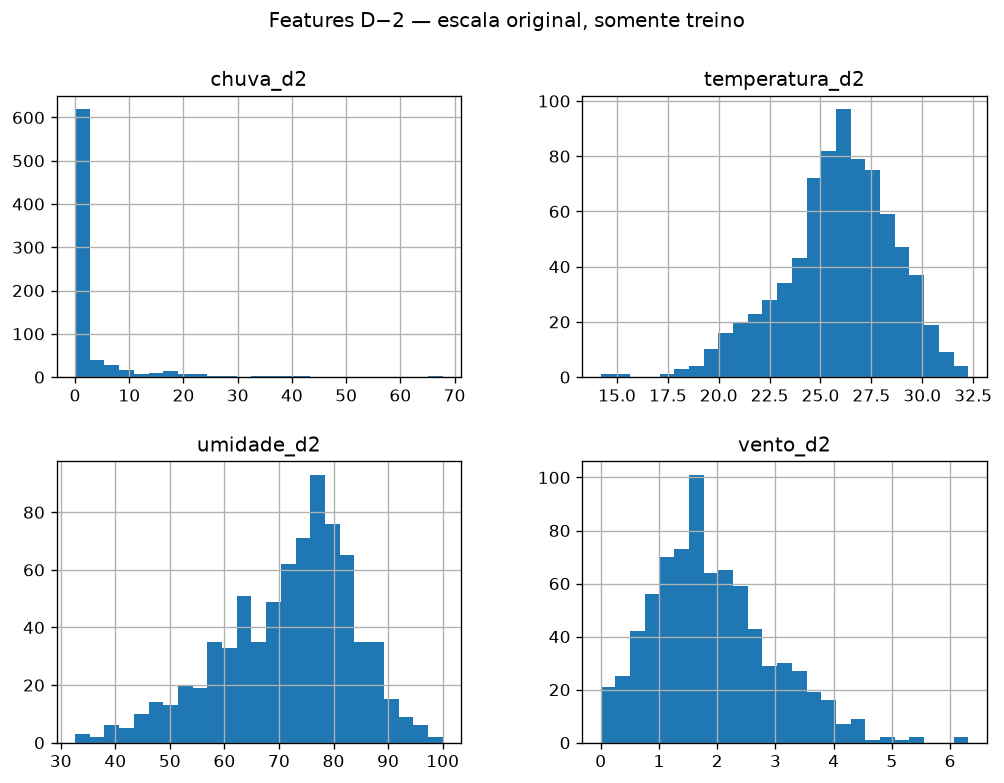

In [3]:
features = ['chuva_d2','temperatura_d2','umidade_d2','vento_d2']
print(training[features].describe().to_string())
print('Ausências:', training[features].isna().sum().to_dict())
q1,q3 = training[features].quantile(.25),training[features].quantile(.75)
iqr=q3-q1
print('Extremos 1,5 IQR:',((training[features]<q1-1.5*iqr)|(training[features]>q3+1.5*iqr)).sum().to_dict())
training[features].hist(bins=25,figsize=(10,7)); plt.suptitle('Features D−2 — escala original, somente treino')


## Correlação com o alvo: Pearson e Spearman

Pearson mede associação linear; Spearman mede associação monotônica por postos. O índice contínuo evita impor distância entre classes. A coluna ordinal baixo=0, medio=1, alto=2 é uma análise complementar; Pearson nessa codificação pressupõe espaçamento artificial. As quatro features e os alvos aparecem nos dois mapas. Município, contagens em D e indicadores futuros são excluídos das features. Associação não demonstra causa ou capacidade de prever fora da amostra; o índice de origem já depende de meteorologia.

pearson                 target_index  target_ordinal
chuva_d2             -0.2430         -0.2208
temperatura_d2        0.2488          0.2503
umidade_d2           -0.5956         -0.5672
vento_d2              0.3572          0.3240
spearman                 target_index  target_ordinal
chuva_d2             -0.4330         -0.3862
temperatura_d2        0.3001          0.2781
umidade_d2           -0.6024         -0.5420
vento_d2              0.3988          0.3392
chuva_d2: associação monotônica negativa com o índice, rho=-0.433.
temperatura_d2: associação monotônica positiva com o índice, rho=0.300.
umidade_d2: associação monotônica negativa com o índice, rho=-0.602.
vento_d2: associação monotônica positiva com o índice, rho=0.399.
Estas associações descrevem o treino; não alteram as escolhas congeladas e não comprovam causalidade.


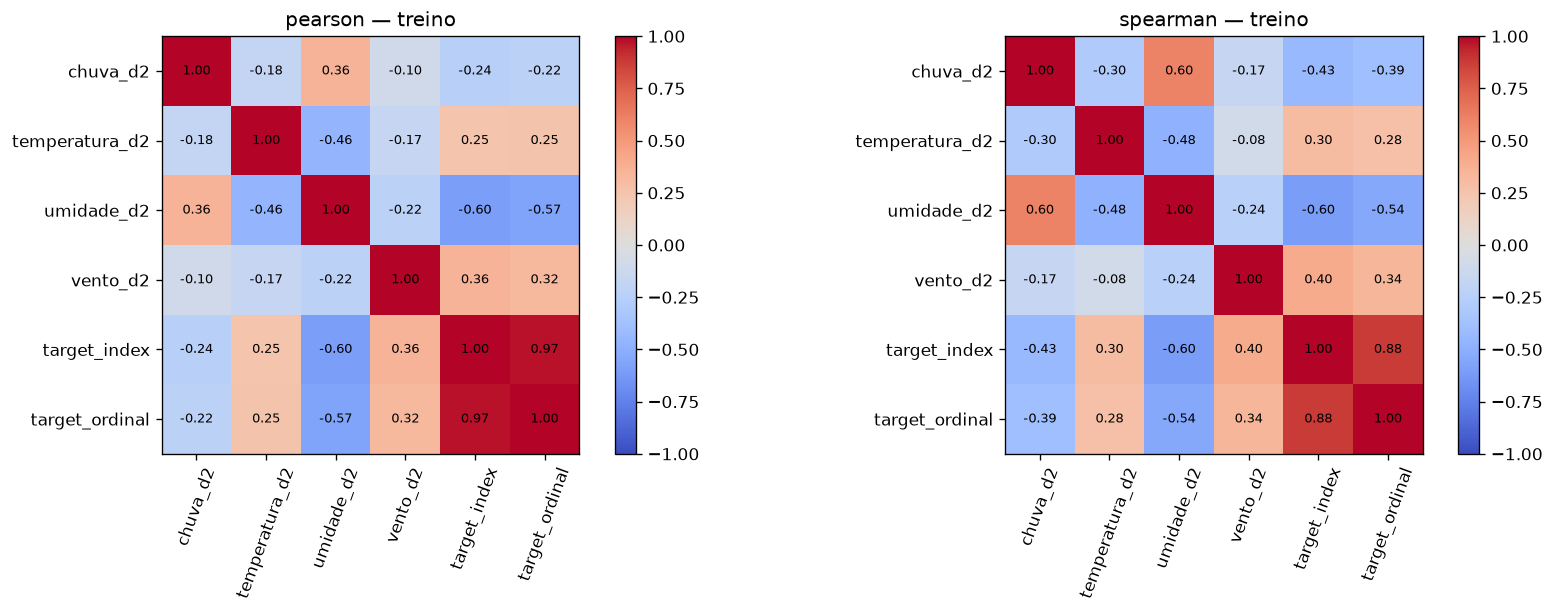

In [4]:
fig, axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
for ax,(method,matrix) in zip(axes,correlations.items()):
    print(method, matrix.loc[features,['target_index','target_ordinal']].round(4).to_string())
    im=ax.imshow(matrix,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(matrix)),matrix.columns,rotation=70); ax.set_yticks(range(len(matrix)),matrix.index)
    for i in range(len(matrix)):
        for j in range(len(matrix)): ax.text(j,i,f'{matrix.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
    ax.set_title(method+' — treino'); fig.colorbar(im,ax=ax)
rho=correlations['spearman'].loc[features,'target_index']
for name,value in rho.items():
    print(f'{name}: associação monotônica {"positiva" if value>0 else "negativa"} com o índice, rho={value:.3f}.')
print('Estas associações descrevem o treino; não alteram as escolhas congeladas e não comprovam causalidade.')


## Hipótese de negócio: umidade e índice alto

Premissa: dias classificados como altos apresentam umidade diferente dos demais dentro de municípios comparáveis. H0: diferenças pareadas simétricas em torno de zero; H1: não simétricas em torno de zero. Wilcoxon bilateral, alfa 0,05, pareamento por município, somente treino. Reutilizamos o resultado registrado antes do teste final; a associação é exploratória e não valida alertas operacionais.

In [5]:
hypothesis=evidence('optimization.json')['hypothesis_training']
print(json.dumps(hypothesis,ensure_ascii=False,indent=2))
print('Interpretação: diferença mediana de umidade',round(hypothesis['median_difference_original_scale'],3),
      '; p-valor',round(hypothesis['p_value'],5),'; rejeita H0 sob as premissas:',hypothesis['reject_under_assumptions'])
print('Seleção por detecções, dependência espacial e construção meteorológica do índice limitam a inferência.')


{
  "status": "computed",
  "municipalities": 15,
  "alpha": 0.05,
  "null": "Distribuição das diferenças pareadas simétrica em torno de zero",
  "sample": "training_only",
  "median_difference_original_scale": -6.083333,
  "limitation": "Exploratório; seleção por detecções, dependência espacial e relação do índice com meteorologia impedem inferência causal.",
  "p_value": 0.00836181640625,
  "reject_under_assumptions": true
}
Interpretação: diferença mediana de umidade -6.083 ; p-valor 0.00836 ; rejeita H0 sob as premissas: True
Seleção por detecções, dependência espacial e construção meteorológica do índice limitam a inferência.
